# 02 · Annotation Analysis

**Artemis-X - AI perception for lunar rock and obstacle detection**

**Objective.** Decide how rock boxes should be derived and which boxes are trustworthy enough to train on (Task B, D.2).

**Research questions**

1. Should labels come from the original CSV (S1), from the semantic masks (S2) or from both?
2. How are uncertain boxes identified and handled?
3. What has, and has not, been verified by humans?

**Inputs (published, pixel-free artifacts)**

- `artifacts/data/strategy_decision.json`
- `artifacts/data/strategy_metrics.json`
- `artifacts/data/annotation_distributions_v1.1.json`
- `artifacts/provenance/VERSIONS.json`

> **Provisional results.** All labels were produced by an automated pipeline (S2-H policy) and have **not** been verified by humans. Metrics are measured on synthetic renders only and do not establish performance on real lunar imagery or readiness for rover deployment.

## Setup
The notebook imports the `artemis_x` package from `src/` and reads only published artifacts. It never trains a model, rebuilds a dataset or evaluates the held-out test split.

In [1]:
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "artemis_x").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from artemis_x.config import paths
from artemis_x.reporting import artifacts as A, plots as P
P.use_style()
pd.set_option("display.precision", 3); pd.set_option("display.max_colwidth", 90)
# Dataset pixels are never committed (redistribution licence unconfirmed). Set ARTEMIS_SHOW_LOCAL_IMAGES=1 to view
# local images when the dataset folder is present.
SHOW_LOCAL_IMAGES = os.environ.get("ARTEMIS_SHOW_LOCAL_IMAGES") == "1" and paths.local_dataset_available()
FIG = paths.ARTIFACTS / "figures"
print("artemis_x ready | local dataset present:", paths.local_dataset_available(), "| showing local images:", SHOW_LOCAL_IMAGES)

artemis_x ready | local dataset present: True | showing local images: False


## 1. Two candidate labelling strategies
- **S1 - CSV boxes:** the original large-rock boxes. They are precise but cover only about 1.9 rocks per image.
- **S2 - mask components:** a box around every connected rock region in the *ground* mask. This gives about 46 boxes per image,
  including small and distant rocks, but some components merge adjacent rocks or are barely visible.

Task B compared both strategies on a stratified sample and selected a **HYBRID (S2-H)** policy. CSV instances are kept as
authoritative. Mask components of at least 50 px are added, merged regions are split by a watershed (neck ratio 0.7), and each box gets
a **visibility** check (edge strength >= 100 or contrast >= 25).

In [2]:
d = A.load_json("data/strategy_decision.json")
k = d["key_numbers"]
pd.Series({"recommended strategy": d["recommended_strategy"], "evaluation ontology": d["evaluation_ontology"],
           "CSV-to-mask match rate (strict)": k["csv_match_rate_V0_strict"],
           "additional S2 candidates >= 50 px per image": k["additional_s2_candidates_ge_50px_per_image_mean"],
           "approved for training (at decision time)": d["approved_for_training"]}).to_frame("value")

,value
recommended strategy,HYBRID
evaluation ontology,"Primary ontology = 'rock' (any visible rock whose box is >= ~50 px area at 720x480, i...."
CSV-to-mask match rate (strict),0.837
additional S2 candidates >= 50 px per image,45.135
approved for training (at decision time),False


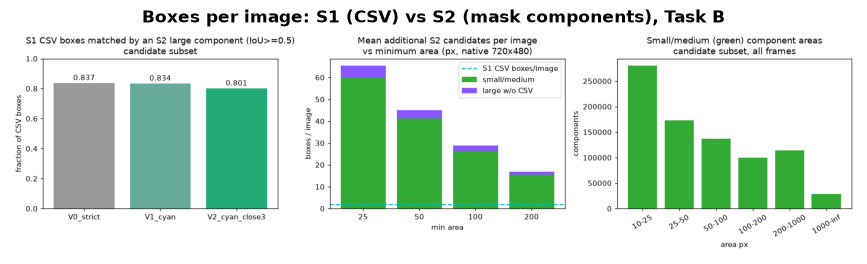

In [3]:
P.show_png(FIG / "b_s1_vs_s2_counts.png", "Boxes per image: S1 (CSV) vs S2 (mask components), Task B")

## 2. Three annotation states
Each candidate box receives exactly one status:

| Status | Meaning | Use |
|---|---|---|
| **VALID** | Clear, visible, unmerged rock | Training target and evaluation ground truth |
| **REVIEW_REQUIRED** | Plausible rock but uncertain (low visibility, possible merge, shadow) | **Never treated as background**: excluded from training scenes (Config A) or masked (Config B), and ignored in evaluation |
| **REJECTED** | Not a usable rock box (degenerate, duplicate, invisible) | Discarded |

In [4]:
A.curated_counts()

,version,policy,status,REJECTED,REVIEW_REQUIRED,VALID
0,curated-dataset-v1,S2-H/1.0,ARCHIVED,49817,192826,261385
1,curated-dataset-v1.1,S2-H/1.1,CURRENT,50005,192784,261239


Why boxes were sent to REVIEW (training split, v1.1):

In [5]:
dist = A.load_json("data/annotation_distributions_v1.1.json")
rr = pd.DataFrame({s: dist[s]["review_reasons"] for s in ("train", "val", "test")}).fillna(0).astype(int)
rr.sort_values("train", ascending=False)

,train,val,test
ambiguous_low_visibility,127788,16161,15760
possible_merge_borderline_split,22678,2818,2831
low_solidity_possible_merge,16682,2061,2119
mostly_in_shadow,2778,364,340
csv_box_in_black_shadow,125,19,23
large_blue_without_csv_likely_merged,107,7,18
overlaps_csv_large_rock,23,1,1


In [6]:
src = pd.DataFrame({s: dist[s]["by_source"] for s in ("train", "val", "test")})
src.loc["total"] = src.sum(); src

,train,val,test
csv_large,14050,1775,1693
mask_blue,17580,2158,2214
mask_blue_split,1725,201,214
mask_green,146389,18069,18277
mask_green_split,29686,3619,3589
total,209430,25822,25987


## 3. Known annotation weaknesses
- **Merged objects:** clusters of touching boulders can form one mask component. Watershed splitting reduces this, and remaining
  low-solidity components go to REVIEW.
- **Duplicates:** overlapping CSV and mask boxes for the same rock were found in Task D. They were removed at the source in curated
  v1.1 (rule D05).
- **Dark and small rocks:** rocks in black shadow or under 50 px are often invisible. They are REVIEW or out of scope, and the
  evaluation ignores them rather than counting them as misses.
- **Mask artefacts:** crater rims, slopes and shadow regions are sometimes labelled as rocks. These were found again in the Task F
  error analysis.

## 4. Human versus automated review

In [7]:
st = A.load_json("data/dataset_status_v1.1.json")
pd.DataFrame([
    {"review": "Task B visual verdicts", "by": "AI assistant (not human)", "items": d["human_review_status"]["rows"], "human decisions": 0},
    {"review": "Task D.2 AI audit of 36 scenes", "by": "AI assistant (not human)", "items": 36, "human decisions": 0},
    {"review": "Human gallery review (E.1b)", "by": "human", "items": st["human_review"]["scenes_reviewed"], "human decisions": st["human_review"]["scenes_reviewed"]},
]).assign(status=lambda x: ["automated only", "automated only", "postponed (hackathon timeline)"])

,review,by,items,human decisions,status
0,Task B visual verdicts,AI assistant (not human),424,0,automated only
1,Task D.2 AI audit of 36 scenes,AI assistant (not human),36,0,automated only
2,Human gallery review (E.1b),human,0,0,postponed (hackathon timeline)


**No annotation has been verified by a human.** The AI-assisted reviews are recorded as *automated* evidence with
`human_review: false`. The dataset status remains **PROVISIONAL, NOT FROZEN**.

## Provenance
Each artifact below is a verified copy (or path-sanitised derivative) of a historical experiment output; `scripts/verify_artifacts.py` re-checks every hash.

In [8]:
A.provenance(['data/strategy_decision.json', 'data/annotation_distributions_v1.1.json', 'provenance/VERSIONS.json'])

,artifact,mode,source (local experiments/),sha256
0,artifacts/data/strategy_decision.json,COPY,experiments/annotation-validation/strategy_decision.json,996c517f740dd02e...
1,artifacts/data/annotation_distributions_v1.1.json,COPY,experiments/yolo-dataset-v1.1/annotation_distributions.json,25c48462c8bf9099...
2,artifacts/provenance/VERSIONS.json,COPY,dataset/processed/VERSIONS.json,da2333f388f38de1...


## Conclusion
- S2-H labels about 15 times more rocks per image than the original CSV. That makes small-rock detection learnable, but also
  makes the labels noisier.
- The three-state policy keeps uncertain rocks out of both the positive and the negative training signal. The ignore-aware
  evaluation in notebook 06 applies the same principle.
- All labels remain automated. The human review (E.1b) is the main open validation gap.

**Next:** [03_data_preprocessing.ipynb](03_data_preprocessing.ipynb)